In [2]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.model_selection import (
    StratifiedShuffleSplit, StratifiedKFold,
    RandomizedSearchCV, cross_val_score
)
#from imblearn.over_sampling import SMOTE
from collections import Counter
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.ensemble import BaggingClassifier
from sklearn.metrics import make_scorer, accuracy_score, f1_score, precision_score, recall_score, matthews_corrcoef

from sklearn.metrics import (confusion_matrix, classification_report)
from skopt import BayesSearchCV
from skopt.space import Real, Categorical, Integer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl
mpl.rcParams['legend.frameon'] = False
mpl.rcParams['font.size'] = 16
mpl.rcParams['font.sans-serif'] = 'Helvetica'
plt.rcParams['axes.unicode_minus'] = False
import matplotlib.patches as mpatches

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, make_scorer
from matplotlib.patches import Patch
from sklearn.preprocessing import MinMaxScaler
import shap
from sklearn.model_selection import cross_validate
import warnings

warnings.filterwarnings('ignore')
import re

/home/digifort/anaconda3/envs/bi2te3_env/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
import os
from typing import List

In [4]:
df = pd.read_csv("/home/digifort/Documents/Research/BiTe_thesis/PCA_analysis//PCA_steps/3PCs/dat_104_samples.csv")

In [5]:
df=df.drop(columns=['structure_filenames'])

In [6]:
structures = list(df.structures)
c_type = list(df.carrier_type)
defect_type = list(df.Defect_Type)

In [7]:
df = df.drop(columns=['structures', 'carrier_type', 'Defect_Type'])
df = df.dropna(axis=1, how='any')

#scaler = StandardScaler()
#df_scaled = pd.DataFrame(scaler.fit_transform(df), columns=df.columns)


#df_scaled['structures'] = structures

### For all models

#### Search Spaces

In [8]:
search_spaces = {
    'RandomForest': {
    'n_estimators': Integer(50, 500), 
    'max_depth': Integer(2, 20),       
    'min_samples_leaf': Integer(3, 8),
    'max_features': Categorical(['sqrt', 'log2']) 
},
    'XGBoost': {
    'n_estimators': Integer(50, 500),    
    'max_depth': Integer(2, 8),          
    'learning_rate': Real(0.01, 0.1),    
    'gamma': Real(0.1, 5.0),             
    'reg_lambda': Real(1.0, 10.0)        
},
    'SVM': {
        'C': Real(0.1, 10, prior='log-uniform'),
        'gamma': Real(1e-4, 1e-1, prior='log-uniform'),
        'kernel': Categorical(['rbf', 'poly', 'sigmoid'])
    },
    'LogisticRegression': {}
}


search_spaces["LogisticRegression"] = [
    {"C": Real(0.01, 10, prior="log-uniform"),
     "penalty": Categorical(["l2"]),
     "solver": Categorical(["saga"]),
     "max_iter": Integer(100, 1000)},
    {"C": Real(0.01, 10, prior="log-uniform"),
     "penalty": Categorical(["l1"]),
     "solver": Categorical(["saga"]),
     "max_iter": Integer(100, 1000)},
    {"C": Real(0.01, 10, prior="log-uniform"),
     "penalty": Categorical(["elasticnet"]),
     "solver": Categorical(["saga"]),
     "l1_ratio": Real(0.0, 1.0),
     "max_iter": Integer(100, 1000)},
    {"penalty": Categorical([None]),
     "solver": Categorical(["saga"]),
     "max_iter": Integer(100, 1000)},
]



#### data

In [9]:
X = df    #.drop(columns=['structures'])
y = pd.Series(c_type, name="carrier_type")

In [10]:
le_y = LabelEncoder()
y_xgb_all = le_y.fit_transform(y) 

### Split data

In [11]:
sss = StratifiedKFold(n_splits=5,  random_state=42, shuffle = True)  #test_size=0.2,
#train_index, test_index = next(sss.split(X, y))
#X_train, X_test = X.iloc[train_index], X.iloc[test_index]
#y_train, y_test = y.iloc[train_index], y.iloc[test_index]

#y_train_xgb = y_xgb[train_index]
#y_test_xgb  = y_xgb[test_index]

In [12]:
y

0      p
1      i
2      p
3      n
4      p
      ..
99     n
100    p
101    p
102    n
103    p
Name: carrier_type, Length: 104, dtype: object

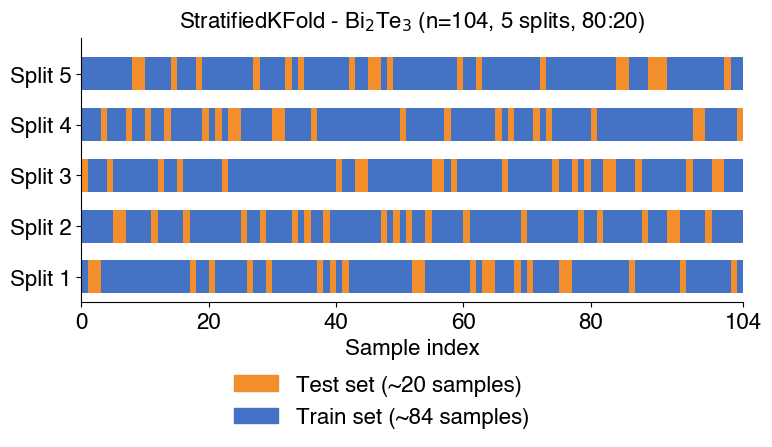

In [ ]:
#plot

#y = np.array(df["carrier_type"])
n_samples = len(y)

# split config
#sss = StratifiedShuffleSplit(n_splits=5, test_size=0.2, random_state=42)

# color
cmap_train = '#4472C4'
cmap_test  = '#F28E2B'
classes    = np.unique(y)
class_colors = {'n': '#5B9BD5', 'p': '#8B4513', 'i': "#E49E4F"}  

# plot
fig, ax = plt.subplots(figsize=(8, 5))

for split_id, (train_idx, test_idx) in enumerate(sss.split(np.arange(n_samples), y)):
    mask = np.zeros(n_samples, dtype=int)
    mask[test_idx] = 1
    for i in range(n_samples):
        color = cmap_test if mask[i] == 1 else cmap_train
        ax.barh(split_id, 1, left=i, height=0.65, color=color, linewidth=0)

# Bottom class distribution row
#for i in range(n_samples):
#    ax.barh(-1, 1, left=i, height=0.65,
#            color=class_colors.get(y[i], '#999999'), linewidth=0)

# axes formatting
ax.set_yticks(list(range(5)))                           #[-1] + 
ax.set_yticklabels([f'Split {i+1}' for i in range(5)], fontsize=16)              #['class'] + 
ax.set_xlabel('Sample index', fontsize=16)
ax.set_xlim(0, n_samples)
ax.set_ylim(-0.5, 4.7)
ax.set_xticks([0, 20, 40, 60, 80, n_samples])
ax.set_title(f'StratifiedKFold - Bi$_2$Te$_3$ (n={n_samples}, 5 splits, 80:20)',
             fontsize=16, pad=8)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# legend
#n_count = np.sum(y == 'n')
#p_count = np.sum(y == 'p')
#i_count = np.sum(y == 'i')
legend_patches = [
    mpatches.Patch(color=cmap_test,               label=f'Test set (~{20} samples)'),   #int(n_samples*0.2)
    mpatches.Patch(color=cmap_train,              label=f'Train set (~{84} samples)'),
    #mpatches.Patch(color=class_colors['n'],  label=f'n-type ({n_count})'),
    #mpatches.Patch(color=class_colors['p'],  label=f'p-type ({p_count})'),
    #mpatches.Patch(color=class_colors['i'],  label=f'i-type ({i_count})'),
]
ax.legend(handles=legend_patches, loc='upper left',
          bbox_to_anchor=(0.2, -0.2), fontsize=16, frameon=False)

plt.tight_layout()
plt.savefig('stratified_shuffle_split.png', dpi=600, bbox_inches='tight')
plt.show()
#print("Saved: stratified_shuffle_split.png")

### cross-validation + scoring configs

In [13]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42) 
f1_weighted = make_scorer(f1_score, average="weighted")

#### estimators

In [14]:
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except Exception:
    HAS_XGB = False

# BayesSearchCV vs RandomizedSearchCV
HAS_SKOPT = True
try:
    from skopt import BayesSearchCV
except Exception:
    HAS_SKOPT = False


#search_spaces["RandomForest"]["pca__n_components"] = Integer(3, 10)
#search_spaces["XGBoost"]["pca__n_components"] = Integer(3, 10)
#search_spaces["SVM"]["pca__n_components"] = Integer(3, 10)

#search_spaces["LogisticRegression"] = [
#    {**d, "pca__n_components": Integer(3, 10)}
#    for d in search_spaces["LogisticRegression"]
#]


estimators = {}

estimators = {
    "RandomForest": RandomForestClassifier(class_weight="balanced", random_state=42),
    "SVM": SVC(class_weight="balanced", random_state=42, probability= True),
    "LogisticRegression": LogisticRegression(class_weight="balanced", random_state=42),
}

if HAS_XGB:
    estimators["XGBoost"] = XGBClassifier(random_state=42)

    


In [15]:
X_raw = df

def prefix_clf_space(space):
    def fix_key(k):
        return k if "__" in k else f"clf__{k}"  

    if isinstance(space, list):
        return [{fix_key(k): v for k, v in d.items()} for d in space]
    return {fix_key(k): v for k, v in space.items()}

search_spaces = {m: prefix_clf_space(sp) for m, sp in search_spaces.items()}

#def prefix_clf_space(space):
#    def fix_key(k):
        # Already pipeline-scoped? keep it
#        if k.startswith(("clf__", "pca__", "scaler__")):
#            return k
        # Otherwise it belongs under the pipeline's clf step
#        return f"clf__{k}"

#    if isinstance(space, list):
#        return [{fix_key(k): v for k, v in d.items()} for d in space]
#    return {fix_key(k): v for k, v in space.items()}

#search_spaces = {m: prefix_clf_space(sp) for m, sp in search_spaces.items()}

In [16]:
def make_pipeline(model_name, n_pcs):
    return Pipeline([
        ("scaler", MinMaxScaler()),
        ("pca", PCA(n_components=n_pcs, random_state=42)),
        ("clf", estimators[model_name]),  
    ])  

#### model order

In [17]:
model_order = ["RandomForest", "XGBoost", "SVM", "LogisticRegression"]
model_order = [m for m in model_order if (m != "XGBoost" or HAS_XGB)]

#### define tuner

In [18]:
def tune_model_fixed_pcs(model_name, Xtr, ytr, n_pcs, n_iter=50):
    pipe = make_pipeline(model_name, n_pcs)
    space = search_spaces[model_name]

    opt = BayesSearchCV(
        estimator=pipe,          
        search_spaces=space,
        n_iter=n_iter,
        cv=cv,
        scoring=f1_weighted,
        n_jobs=-1,
        optimizer_kwargs={"n_initial_points": 10},
        random_state=42,
        verbose=0
    )
    opt.fit(Xtr, ytr)
    return opt.best_estimator_, opt.best_params_

#### PCA analysis on all models

In [19]:
df1 = pd.read_csv("/home/digifort/Documents/Research/BiTe_thesis/PCA_analysis//PCA_steps/3PCs/dat_104_samples.csv")
meta = df1[["structures", "carrier_type", "Defect_Type"]].copy()

In [20]:
pc_min, pc_max = 3, 11 
rows_all = []

out_dir = "/home/digifort/Documents/Research/BiTe_thesis/PCA_analysis/PCA_steps/splits_csv"
os.makedirs(out_dir, exist_ok=True)

for split_id, (train_index, test_index) in enumerate(sss.split(X_raw, y), start=1):
    X_train, X_test = X_raw.iloc[train_index], X_raw.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]
    y_train_xgb = y_xgb_all[train_index]

    # save the training and test sets per split
   # train_df = X_train.copy()
   # train_df["carrier_type"] = y_train.values
   # train_df["carrier_type_enc"] = y_train_xgb  

   # test_df = X_test.copy()
   # test_df["carrier_type"] = y_test.values
   # test_df["carrier_type_enc"] = y_xgb_all[test_index] 

   # train_path = os.path.join(out_dir, f"split_{split_id:02d}_train.csv")
   # test_path  = os.path.join(out_dir, f"split_{split_id:02d}_test.csv")

   # train_df.to_csv(train_path, index=False)
   # test_df.to_csv(test_path, index=False)

    # slice metadata with the same indices
    meta_train = meta.iloc[train_index].copy()
    meta_test  = meta.iloc[test_index].copy()

    # add structure ids (and any other metadata you want) into saved files
    train_df = X_train.copy()
    train_df.insert(0, "structures", meta_train["structures"].values)   # keep as first column
    train_df["carrier_type"] = meta_train["carrier_type"].values
    train_df["carrier_type_enc"] = y_xgb_all[train_index]
    train_df["Defect_Type"] = meta_train["Defect_Type"].values

    test_df = X_test.copy()
    test_df.insert(0, "structures", meta_test["structures"].values)
    test_df["carrier_type"] = meta_test["carrier_type"].values
    test_df["carrier_type_enc"] = y_xgb_all[test_index]
    test_df["Defect_Type"] = meta_test["Defect_Type"].values

    train_path = os.path.join(out_dir, f"split_{split_id:02d}_train.csv")
    test_path  = os.path.join(out_dir, f"split_{split_id:02d}_test.csv")

    train_df.to_csv(train_path, index=False)
    test_df.to_csv(test_path, index=False)


    for n_pcs in range(pc_min, pc_max):
        for model_name in model_order:

            if model_name == "XGBoost":
                best_est, best_params = tune_model_fixed_pcs(
                    model_name, X_train, y_train_xgb, n_pcs=n_pcs, n_iter=50
                )
               # cv_scores = cross_val_score(best_est, X_train, y_train_xgb,
               #                             scoring=f1_weighted, cv=cv, n_jobs=-1)
                
                scoring = f1_weighted  
                cv_out = cross_validate(
                    best_est, X_train, y_train_xgb,
                    scoring=scoring, cv=cv, n_jobs=-1,
                    return_train_score=True
                    )
                
                y_pred_train_enc = best_est.fit(X_train, y_train_xgb).predict(X_train)
                y_pred_enc = best_est.fit(X_train, y_train_xgb).predict(X_test)
                y_pred = le_y.inverse_transform(y_pred_enc)
                y_pred_train = le_y.inverse_transform(y_pred_train_enc)


            else:
                best_est, best_params = tune_model_fixed_pcs(
                    model_name, X_train, y_train, n_pcs=n_pcs, n_iter=50
                )
                scoring = f1_weighted
                cv_out = cross_validate(best_est, X_train, y_train,
                                        scoring=scoring, cv=cv, n_jobs=-1,
                                        return_train_score=True)
                #cv_scores = cross_val_score(best_est, X_train, y_train,
                #                            scoring=f1_weighted, cv=cv, n_jobs=-1)
                y_pred_train = best_est.fit(X_train, y_train).predict(X_train)
                y_pred = best_est.fit(X_train, y_train).predict(X_test)

            train_scores = cv_out["train_score"]
            val_scores   = cv_out["test_score"]


            rows_all.append({"Split": split_id,
                             "Model": model_name,
                             "PCs_Used": n_pcs,
                             "Train_F1_weighted_mean": float(np.mean(train_scores)),
                             "Train_F1_weighted_std": float(np.std(train_scores, ddof=1)),
                             "CV_F1_weighted_mean": float(np.mean(val_scores)),
                             "CV_F1_weighted_std": float(np.std(val_scores, ddof=1)),
                             "Train_F1_weighted" : float(f1_score(y_train, y_pred_train, average="weighted")),
                             "Test_F1_weighted": float(f1_score(y_test, y_pred, average="weighted")),
                             "Best_Params": best_params,
                             })
            #rows_all.append({
            #    "Split": split_id,
            #    "Model": model_name,
            #    "PCs_Used": n_pcs,
            #    "CV_F1_weighted_mean": float(cv_scores.mean()),
            #    "CV_F1_weighted_std": float(cv_scores.std(ddof=1)),
            #    "Test_F1_weighted": float(f1_score(y_test, y_pred, average="weighted")),
            #    "Best_Params": best_params,
            #})

summary_all = pd.DataFrame(rows_all)

/home/digifort/anaconda3/envs/bi2te3_env/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/digifort/anaconda3/envs/bi2te3_env/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/digifort/anaconda3/envs/bi2te3_env/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/digifort/anaconda3/envs/bi2te3_env/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/digifort/anaconda3/envs/bi2te3_env/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not conver

In [21]:
summary_all

,Split,Model,PCs_Used,Train_F1_weighted_mean,Train_F1_weighted_std,CV_F1_weighted_mean,CV_F1_weighted_std,Train_F1_weighted,Test_F1_weighted,Best_Params
0,1,RandomForest,3,0.932294,0.019568,0.869165,0.162027,0.940336,0.597599,"{'clf__max_depth': 17, 'clf__max_features': 'l..."
1,1,XGBoost,3,0.993331,0.007030,0.860613,0.127833,1.000000,0.673882,"{'clf__gamma': 0.1, 'clf__learning_rate': 0.01..."
2,1,SVM,3,0.939941,0.010794,0.878585,0.132473,0.941248,0.820068,"{'clf__C': 10.0, 'clf__gamma': 0.0585164713922..."
3,1,LogisticRegression,3,0.861251,0.023730,0.777940,0.116726,0.856320,0.690021,"{'clf__C': 4.006116799510186, 'clf__max_iter':..."
4,1,RandomForest,4,0.959443,0.015661,0.875417,0.122519,0.964743,0.698186,"{'clf__max_depth': 5, 'clf__max_features': 'sq..."
...,...,...,...,...,...,...,...,...,...,...
155,5,LogisticRegression,9,0.934916,0.013644,0.894740,0.129851,0.941415,0.898701,"{'clf__C': 0.381354981015985, 'clf__max_iter':..."
156,5,RandomForest,10,0.990803,0.008871,0.916301,0.098430,0.988172,0.897817,"{'clf__max_depth': 19, 'clf__max_features': 's..."
157,5,XGBoost,10,0.997370,0.005545,0.903629,0.125805,1.000000,0.897817,"{'clf__gamma': 0.4805302469951146, 'clf__learn..."
158,5,SVM,10,0.951705,0.008639,0.906067,0.090295,0.941553,0.886693,"{'clf__C': 10.0, 'clf__gamma': 0.0547148129200..."


#### save data

In [23]:
out_dir = "/home/digifort/Documents/Research/BiTe_thesis/my_paper/classifier"
os.makedirs(out_dir, exist_ok=True)

#summary_all = pd.DataFrame(rows_all)
csv_path = os.path.join(out_dir, "PC_analysis_fin_2.csv")
summary_all.to_csv(csv_path, index=False)
print("Wrote:", csv_path)

Wrote: /home/digifort/Documents/Research/BiTe_thesis/my_paper/classifier/PC_analysis_fin_2.csv
